In [ ]:
outpath = '/content/drive/MyDrive/John/Work/Research/01_In_Progress/ResearchMaterial/Deep Learning/code/'

In [ ]:
pip install torch torchvision matplotlib numpy scikit-learn umap-learn

In [1]:
# --- Celda 1: imports ---
import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device)

torch.manual_seed(0); np.random.seed(0)

Device: cpu


In [2]:
# --- Celda 2: carga MNIST ---
tf = transforms.ToTensor()   # [0,1], (1,28,28)
train_ds = datasets.MNIST('./data', train=True,  download=True, transform=tf)
test_ds  = datasets.MNIST('./data', train=False, download=True, transform=tf)
train_loader = DataLoader(train_ds, batch_size=100, shuffle=True)
test_loader  = DataLoader(test_ds,  batch_size=100, shuffle=False)
print(f"Train: {len(train_ds)}  Test: {len(test_ds)}")

100%|██████████| 9.91M/9.91M [00:00<00:00, 60.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.69MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.9MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.4MB/s]

Train: 60000  Test: 10000


In [ ]:
# --- Celda 3: definición del MLP ---
class MLPClassifier(nn.Module):
    def __init__(self, hidden=256, num_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),                        # 28x28 -> 784  (¡aquí perdemos topología!)
            nn.Linear(28*28, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, num_classes),
        )
    def forward(self, x): return self.net(x)

mlp = MLPClassifier(256).to(device)
n_params = sum(p.numel() for p in mlp.parameters())
print(f"Parámetros MLP: {n_params:,}")

Parámetros MLP: 269,322


In [ ]:
# --- Celda 4: Evolución de paramétros ---
# Regla: Linear(D_in, D_out) añade D_in*D_out + D_out parámetros
def params_una_capa_oculta(side, hidden=256, out=10):
    d = side*side
    return d*hidden + hidden + hidden*out + out

print("Parámetros solo en la PRIMERA capa oculta (D_in → 256):")
for side in [28, 64, 128, 224]:
    n = params_una_capa_oculta(side)
    print(f"  {side:>3}x{side:<3} -> {n:>12,}")

print("\nConclusión: pasar de MNIST (28²) a ImageNet (224²)")
print(f"multiplica los pesos por {(224/28)**2:.0f}x en cada capa densa.")

Parámetros solo en la PRIMERA capa oculta (D_in → 256):
   28x28  ->      203,530
   64x64  ->    1,051,402
  128x128 ->    4,197,130
  224x224 ->   12,847,882

Conclusión: pasar de MNIST (28²) a ImageNet (224²)
multiplica los pesos por 64x en cada capa densa.


In [ ]:
# --- Celda 5: entrenamiento de clasificación ---
def train_cls(model, loader, epochs=5, lr=1e-3):
    crit = nn.CrossEntropyLoss()
    opt  = optim.Adam(model.parameters(), lr=lr)
    for ep in range(epochs):
        model.train(); correct = total = 0
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x);
            loss = crit(out, y)
            opt.zero_grad();
            loss.backward();
            opt.step()
            correct += (out.argmax(1) == y).sum().item(); total += y.size(0)
        print(f"ep {ep+1} | train acc = {correct/total:.4f}")

train_cls(mlp, train_loader, epochs=5)

def evaluate(model, loader):
    model.eval(); correct = total = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            correct += (model(x).argmax(1) == y).sum().item()
            total += y.size(0)
    return correct/total

print(f"Test acc MLP: {evaluate(mlp, test_loader):.4f}")

ep 1 | train acc = 0.9097
ep 2 | train acc = 0.9633
ep 3 | train acc = 0.9755
ep 4 | train acc = 0.9818
ep 5 | train acc = 0.9869
Test acc MLP: 0.9779


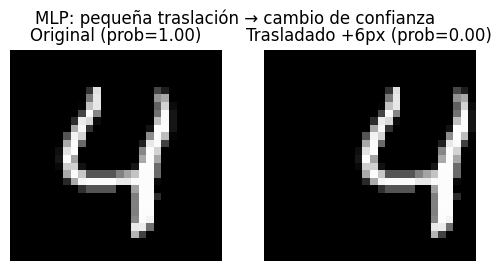

In [ ]:
# --- Celda 6: El MLP NO tiene invariancia a la traslación ---
# Tomamos un '4' del test y lo trasladamos 6 px. La predicción del MLP cambia.
x0, y0 = test_ds[4]
x0 = x0.unsqueeze(0).to(device)
shifted = torch.roll(x0, shifts=6, dims=3)   # +6 px a la derecha

with torch.no_grad():
    p_orig = mlp(x0).softmax(1)[0, y0].item()
    p_shift = mlp(shifted).softmax(1)[0, y0].item()

fig, ax = plt.subplots(1, 2, figsize=(6, 3))
ax[0].imshow(x0[0,0].cpu(), cmap='gray')
ax[0].set_title(f"Original (prob={p_orig:.2f})"); ax[0].axis('off')
ax[1].imshow(shifted[0,0].cpu(), cmap='gray')
ax[1].set_title(f"Trasladado +6px (prob={p_shift:.2f})"); ax[1].axis('off')
plt.suptitle("MLP: pequeña traslación → cambio de confianza")
plt.show()

# Guardamos este modelo para comparar en el siguiente notebook
torch.save(mlp.state_dict(), f'{outpath}/mlp_mnist.pt')